# Which GPU work did PyTorch launch?

`capture` profiles one warmed-up training step and returns `prof.events()`.
`rows` holds every event once, with `launcher_id` pointing at the event that
launched it (a CPU op's `cpu_parent`, or a kernel's CUDA launch call), so
`aten::mm -> cudaLaunchKernel -> kernel` is a chain of `launcher_id` links.

Module hooks record `forward::<module_fqn>` scopes, and autograd node hooks restore
the same path as `backward::<module_fqn>` during backward. A kernel belongs to its
nearest module scope; with none it is `<unattributed>`. `aggregate_kernels` does the
attribution and raises if a kernel is owned by a module but never reaches the root scope.

1. Setup and capture
2. Every kernel with its module
3. Time per module
4. Timeline
5. FLOPs check
6. Appendix: what each id is, and one kernel's launch chain

In [1]:
import pandas as pd
import torch
from profile_events import (
    aggregate_kernels,
    allocations_by_label,
    display_timeline,
    events_to_rows,
    launch_chain,
    memory_over_time,
    transformer_matmul_comparison,
)

from models.transformer import Transformer

model = Transformer(
    vocab_size=10000,
    d_model=512,
    d_ff=1344,
    sequence_length=256,
    num_layers=4,
    num_heads=16,
    rope_theta=10000,
    device="cuda",  # has to agree with app.GPU; the preflight checks it
    dtype="torch.float32",  # strings parsed in the worker container
)

# model = Transformer(
#     vocab_size=10000,
#     d_model=32,
#     d_ff=128,
#     sequence_length=4,
#     num_layers=4,
#     num_heads=2,
#     rope_theta=10000,
#     device="cuda",  # has to agree with app.GPU; the preflight checks it
#     dtype="torch.float32",  # strings parsed in the worker container
# )


### What `capture` does

`capture` runs on a GPU worker: a plain warmup loop, then a measured loop over the same training step. Every input is passed explicitly in the call below.

1. Build the model, optimizer and random tokens.
2. Run `warmup_steps` plain steps, then synchronize.
3. Run `profile_steps` steps, each under the instruments `capture`'s switches turn on, and each ending in a synchronize. Both loops run forward and loss under `autocast`. Each phase of the step is wrapped in `record_function`, so it shows up by name: `train::zero_grad`, `train::forward`, `train::loss`, `train::backward`, `train::optimizer_step`.
4. Return each step's readings (profiler `events`, memory peaks, allocator `snapshot` and `wall_clock_part_times`) under `steps`, each device's `total_memory` and the `size_estimation` of the model and the optimizer state.

`capture` takes one keyword switch per instrument: `profile`, `module_scopes`, `peak` (peak allocated and reserved per step), `trace` (each step's allocator trace, behind the memory plot) and `wall_clock` (each part of the step timed between synchronizes). `kernel_events` and `memory_capture` are context managers that do nothing when their switch is off.

**`record_function(name)`** adds a `user_annotation` event with that name. It is a label we add, not an operation PyTorch ran. Anything that starts and ends inside its time span becomes its child, so parent and child are decided by timestamps.

**`module_scopes(model)`** does the same per module: `forward::<module>` around each module's forward call, and `backward::<module>` around the backward work it owns. Later, a kernel is assigned to the module whose scope contains its launch.

A typical start of the events, in order, with start and end times in microseconds (illustrative values; the ids are from a real capture). `device_type` says where an event executed, CPU or GPU. Each indented row is a child of the row above it that is one level less indented. Annotations are ours, the rest is PyTorch:

```
                                       device_type      activity_type                     correlation_id  linked_correlation_id  start   end
train::zero_grad                       DeviceType.CPU   user_annotation            1 (frontend, PyTorch)                      0      0    40
  Optimizer.zero_grad#AdamW.zero_grad  DeviceType.CPU   user_annotation (PyTorch)  2 (frontend, PyTorch)                      0      5    35
train::forward                         DeviceType.CPU   user_annotation            3 (frontend, PyTorch)                      0     40  4200
  forward::model                       DeviceType.CPU   user_annotation            4 (frontend, PyTorch)                      0     45  4190
    forward::model.embedding           DeviceType.CPU   user_annotation            5 (frontend, PyTorch)                      0     50   300
      aten::index                      DeviceType.CPU   cpu_op                     6 (frontend, PyTorch)                      0     60   290
        cudaLaunchKernel               DeviceType.CPU   cuda_runtime                 11 (backend, CUPTI)  6 (frontend, PyTorch)    100   120
          vectorized_gather_kernel     DeviceType.CUDA  kernel (on the GPU)          11 (backend, CUPTI)  6 (frontend, PyTorch)    130   142
```

**Linking.** Parent and child among CPU events come from the timestamps, as above. A GPU event has no CPU parent in the trace, so `link_events` finds its launcher with correlation ids.

**CUDA** is NVIDIA's platform for running programs on its GPUs. It has a CPU side and a GPU side:

- On the CPU, the CUDA runtime library (`cuda_runtime` events, e.g. `cudaLaunchKernel`, `cudaMemcpyAsync`) and the lower-level driver it calls into (`cuda_driver`). These are ordinary CPU function calls that queue work for the GPU and return immediately.
- On the GPU, the work that was queued: `kernel`, `gpu_memcpy`, `gpu_memset`.

The `correlation_id` column holds ids from two separate namespaces, and the same number can appear in both. The boundary is who recorded the event, not CPU versus GPU:

- **Frontend:** events PyTorch's own profiler records for the operations your Python code calls: `cpu_op` and `user_annotation`. PyTorch numbers them with its own counter (1 to 6 above).
- **Backend:** every event of the CUDA layer, recorded by CUPTI, NVIDIA's profiling library (the CUDA Profiling Tools Interface). That is both the CPU-side CUDA calls (`cuda_runtime`, `cuda_driver`) and the GPU work they launch (`kernel`, `gpu_memcpy`, `gpu_memset`). CUPTI numbers them with its own counter (11 above), and a kernel gets the same id as the call that launched it.

So `device_type` is not the namespace boundary. `cudaLaunchKernel` has `DeviceType.CPU` because it executes on the CPU, yet its `correlation_id` is a backend id. `DeviceType.CUDA` marks only the GPU-side events, so it is not a name for the whole backend namespace. The namespace follows `activity_type`.

`linked_correlation_id` crosses between them. On a launch call or GPU event it holds the frontend `correlation_id` of the op that issued the launch (6, `aten::index`).

`link_events` keeps one lookup per namespace, so an id is only ever compared with ids of its own kind:

1. A kernel's backend `correlation_id` is looked up among the launch calls, so it is matched to the `cuda_runtime` call that launched it (11).
2. The launch call's `linked_correlation_id` is looked up among the frontend ids, so the call is matched to the op that issued it (6).

Each match sets `launcher_id` to the matched event's row. Following `launcher_id` from the kernel gives `kernel -> cudaLaunchKernel -> aten::index -> forward::model.embedding -> ...`, which is how a kernel finds its module scope. If a match is missing or ambiguous, `launcher_id` stays empty and the kernel is unattributed. See "What each id is" in the appendix.

In [11]:
from contextlib import contextmanager

from torch.profiler import ProfilerActivity, profile


@contextmanager
def capture_profiler_events(enabled):
    """Yield a list that holds the block's profiler events once it exits; empty when not enabled.

    It synchronizes before the profiler stops, so every kernel launched inside the block is recorded.
    """
    events = []
    if not enabled:
        yield events
        return
    with profile(activities=[ProfilerActivity.CPU, ProfilerActivity.CUDA], with_flops=True) as prof:
        yield events
        torch.cuda.synchronize()
    events.extend(prof.events())


@contextmanager
def capture_memory(peak=False, trace=False, max_entries=100_000):
    """Yield a dict that holds the block's memory readings once it exits; empty when both are off.

    peak adds peak_allocated and peak_reserved bytes; trace adds the allocator snapshot of just
    this block under "snapshot".
    """
    memory = {}
    if peak:
        torch.cuda.reset_peak_memory_stats()
    if trace:
        torch.cuda.memory._record_memory_history(max_entries=max_entries, clear_history=True)
    try:
        yield memory
        if trace:
            memory["snapshot"] = torch.cuda.memory._snapshot()
    finally:
        if trace:
            torch.cuda.memory._record_memory_history(enabled=None)
    if peak:  # allocator statistics are kept on the CPU, so no synchronize is needed
        memory["peak_allocated"] = torch.cuda.max_memory_allocated()
        memory["peak_reserved"] = torch.cuda.max_memory_reserved()


In [12]:
import modal

import main

app = modal.App("profile-events")
# The worker image, so its torch is the uv.lock version that unpickles the events locally.
# The container imports profile_events for module_scopes.
image = main.worker_image.add_local_python_source("profile_events")


@app.function(image=image, gpu="L4", timeout=600)
def capture(
    declaration, *, warmup_steps, profile_steps, autocast,
    kernel_events, module_scopes, peak, trace, wall_clock,
) -> dict:
    """Return the measured loop's results after a plain warmup loop over the same model and optimizer.

    autocast is the dtype forward and loss run in, or None; warmup and the measured loop share it,
    so warmup prepares the same kernels. The switches pick the instruments around every measured
    step: kernel_events (torch profiler), module_scopes (forward::/backward:: annotations), peak (peak
    allocated and reserved bytes), trace (the allocator trace) and wall_clock (each part
    of the step timed between synchronizes, in ms, under "wall_clock_part_times" keyed by part
    name). Every measured step ends in a synchronize. The result has "steps" ({step: {"events",
    and capture_memory's readings}}), "size_estimation" ({"model", "optimizer"}, each with
    parameters and bytes), "persistent_memory" (bytes of weights, gradients and optimizer state)
    and "device_vram" (total bytes on the GPU).
    """
    import time
    from contextlib import contextmanager, nullcontext

    import profile_events
    import torch
    from torch import nn
    from torch.profiler import record_function

    torch.manual_seed(0)
    model = declaration.build()
    # model = torch.compile(model)
    tokens = torch.randint(
    0, declaration.vocab_size, (8, declaration.sequence_length),
    generator=torch.Generator().manual_seed(0)).to(declaration.device)
    model.train()
    optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3)
    # Next-token prediction: each position predicts the following input token.
    targets = tokens[:, 1:].reshape(-1)
    precision = torch.autocast("cuda", dtype=autocast) if autocast else nullcontext()

    part_ms = {}

    @contextmanager
    def part(name):
        """Wrap one part of the step in train::<name>; with wall_clock, time it between synchronizes."""
        with record_function(f"train::{name}"):
            if not wall_clock:
                yield
                return
            torch.cuda.synchronize()
            start = time.perf_counter()
            yield
            torch.cuda.synchronize()
            part_ms[name] = (time.perf_counter() - start) * 1e3

    def train_step():
        with part("zero_grad"):
            optimizer.zero_grad(set_to_none=True)
        with precision:  # backward and the optimizer run outside autocast
            with part("forward"):
                logits = model(tokens)
            with part("loss"):
                loss = nn.functional.cross_entropy(
                    logits[:, :-1, :].reshape(-1, logits.shape[-1]), targets
                )
        with part("backward"):
            loss.backward()
        with part("optimizer_step"):
            optimizer.step()

    for _ in range(warmup_steps):
        train_step()
    # Finish warmup first, so none of its queued kernels land in the measured loop.
    torch.cuda.synchronize()

    def size_of(tensors):
        tensors = list(tensors)
        return {"parameters": sum(t.numel() for t in tensors),
                "bytes": sum(t.numel() * t.element_size() for t in tensors)}

    # Optimizer state exists only after the first step.
    size_estimation = {
        "model": size_of(model.parameters()),
        "optimizer": size_of(t for state in optimizer.state.values() for t in state.values() if torch.is_tensor(t)),
    }

    steps = {}
    for step in range(profile_steps):
        # Entered top to bottom and closed in reverse: module scopes close before the profiler stops.
        with (
            capture_memory(peak, trace) as readings,
            capture_profiler_events(kernel_events) as events,
            profile_events.module_scopes(model) if module_scopes else nullcontext(),
        ):
            train_step()
            torch.cuda.synchronize()
        steps[step] = {"events": events, **readings}
        if wall_clock:
            steps[step]["wall_clock_part_times"] = dict(part_ms)

    return {
        "steps": steps,
        "size_estimation": size_estimation,
        # Gradients are the size of the weights, so persistent memory counts the model twice.
        "persistent_memory": 2 * size_estimation["model"]["bytes"] + size_estimation["optimizer"]["bytes"],
        "device_vram": torch.cuda.get_device_properties(torch.cuda.current_device()).total_memory,
    }

In [13]:
with modal.enable_output(), app.run():  # streams the image build and the container's logs here
    captured = capture.remote(
        model,
        warmup_steps=5,
        profile_steps=10,
        autocast=torch.bfloat16,  # or None for full precision
        kernel_events=True,
        module_scopes=True,
        peak=True,
        trace=True,
        wall_clock=True,
    )

✓ Initialized. View run at 
https://modal.com/apps/ocanphys/main/ap-hDorcYfGOPHVxuj3JpNLpO
⠋ Initializing...
⠸ Creating objects...objects...
├── ⠋ Creating mount PythonPackage:profile_events: Finalizing index of 1 files
⠦ Creating objects...
├── ⠸ Creating mount PythonPackage:profile_events: Finalizing index of 1 files
└── ⠸ Creating mount PythonPackage:config, PythonPackage:system, 
    PythonPackage:launcher, PythonPackage:artifacts, PythonPackage:models: 
⠏ Creating objects...
├── 🔨 Created mount PythonPackage:profile_events
└── ⠦ Creating mount PythonPackage:config, PythonPackage:system, 
    PythonPackage:launcher, PythonPackage:artifacts, PythonPackage:models: 
⠹ Creating objects...
├── 🔨 Created mount PythonPackage:profile_events
├── 🔨 Created mount PythonPackage:config, PythonPackage:system, 
│   PythonPackage:launcher, PythonPackage:artifacts, PythonPackage:models
⠸ Creating objects...
├── 🔨 Created mount PythonPackage:profile_events
├── 🔨 Created mount PythonPackage:config, P

## Timeline

step 3: 10464 events
827 kernels, 97 unattributed


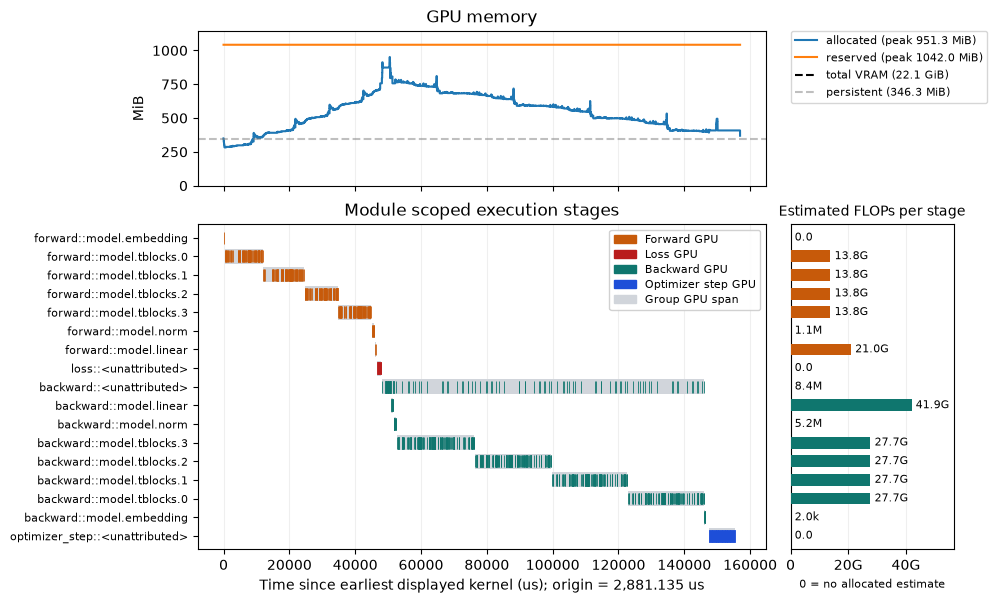

In [14]:
# Downstream cells look at one measured step; the last is the furthest from warmup.
step = 3
function_events = captured["steps"][step]["events"]
memory_snapshot = captured["steps"][step]["snapshot"]
size_estimation, persistent_memory, device_vram = (
    captured["size_estimation"], captured["persistent_memory"], captured["device_vram"])
rows = events_to_rows(function_events)
print(f"step {step}: {len(function_events)} events")
# Raises if a module-owned kernel never reaches the root scope.
groups, kernels, unattributed_kernels, flop_sources = aggregate_kernels(rows, depth=3)
print(f"{len(kernels)} kernels, {len(unattributed_kernels)} unattributed")
# Unattributed kernels show module_fqn "<unattributed>".
kernel_table = kernels[["name", "phase", "module_fqn", "owner_fqn", "duration_us", "gpu_start_us", "device_memory_usage", "cpu_memory_usage"]].sort_values('device_memory_usage')
# display(kernel_table)
# display(groups[["kernel_count", "gpu_time_us", "gpu_span_us", "estimated_flops"]])
usage = memory_over_time(memory_snapshot)[0]
display_timeline(groups, kernels, figsize=(10, 6), show_flops=True, memory=usage, total_memory=device_vram,
                 persistent_memory=persistent_memory)

In [6]:
import matplotlib.pyplot as plt

# One line per measured step, each from its own first allocator event; darker is later.
fig, (allocated_ax, reserved_ax) = plt.subplots(2, 1, sharex=True, figsize=(10, 6))
count = len(captured["steps"])
for index, (step, readings) in enumerate(captured["steps"].items()):
    color = plt.cm.Blues(0.35 + 0.65 * index / max(count - 1, 1))
    usage = memory_over_time(readings["snapshot"])[0]
    usage = usage.set_axis((usage.index - usage.index[0]) / 1e3).div(2**20)  # ms and MiB
    allocated_ax.step(usage.index, usage["allocated"], where="post", color=color, linewidth=1, label=f"step {step}")
    reserved_ax.step(usage.index, usage["reserved"], where="post", color=color, linewidth=1)
allocated_ax.set(ylabel="allocated (MiB)", title="GPU memory in every measured step")
reserved_ax.set(ylabel="reserved (MiB)", xlabel="ms since the step's first allocator event")
allocated_ax.legend(fontsize=8, ncol=2)
fig.tight_layout()

## Appendix

step 3: 1579 events
327 kernels, 327 unattributed


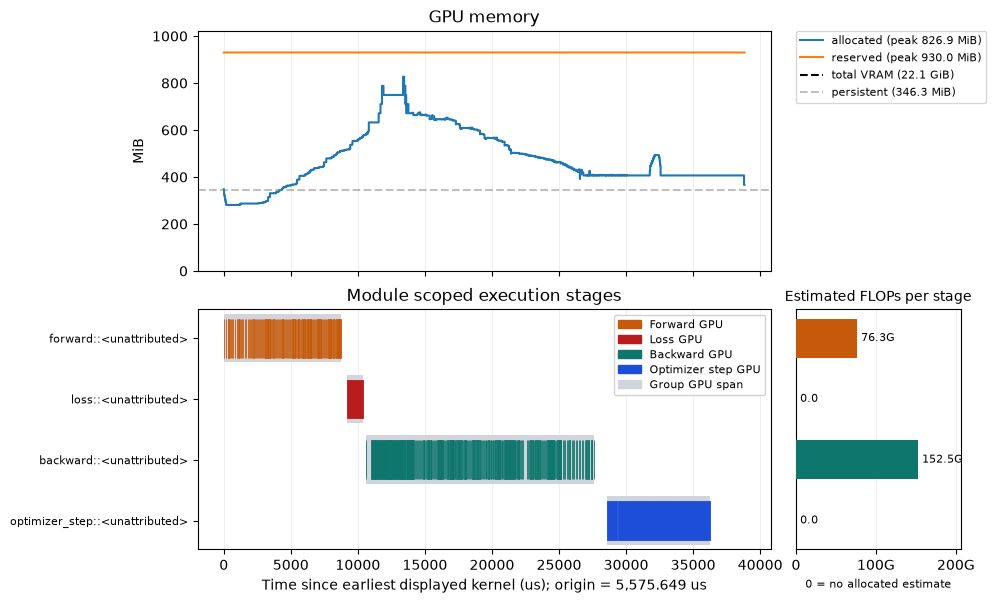

In [10]:
# Downstream cells look at one measured step; the last is the furthest from warmup.
step = 3
function_events = captured["steps"][step]["events"]
memory_snapshot = captured["steps"][step]["snapshot"]
size_estimation, persistent_memory, device_vram = (
    captured["size_estimation"], captured["persistent_memory"], captured["device_vram"])
rows = events_to_rows(function_events)
print(f"step {step}: {len(function_events)} events")
# Raises if a module-owned kernel never reaches the root scope.
groups, kernels, unattributed_kernels, flop_sources = aggregate_kernels(rows, depth=3)
print(f"{len(kernels)} kernels, {len(unattributed_kernels)} unattributed")
# Unattributed kernels show module_fqn "<unattributed>".
kernel_table = kernels[["name", "phase", "module_fqn", "owner_fqn", "duration_us", "gpu_start_us", "device_memory_usage", "cpu_memory_usage"]].sort_values('device_memory_usage')
# display(kernel_table)
# display(groups[["kernel_count", "gpu_time_us", "gpu_span_us", "estimated_flops"]])
usage = memory_over_time(memory_snapshot)[0]
display_timeline(groups, kernels, figsize=(10, 6), show_flops=True, memory=usage, total_memory=device_vram,
                 persistent_memory=persistent_memory)

## What each id is

`correlation_id` is `FunctionEvent.id`, which `_parse_kineto_results` fills with
`kineto_event.correlation_id()`. What it counts depends on the kind of row:

| Row (`activity_type`) | `correlation_id` | `linked_correlation_id` | `external_id` |
| --- | --- | --- | --- |
| Frontend: op or `record_function` scope (`cpu_op`, `user_annotation`) | PyTorch's own counter | 0 | `correlation_id` |
| Launch call on the CPU (`cuda_runtime`, `cuda_driver`) | CUPTI's counter | the op's `correlation_id` | `linked_correlation_id` |
| GPU work (`kernel`, `gpu_memcpy`, `gpu_memset`) | CUPTI's counter, equal to its launch call's | the op's `correlation_id` | `linked_correlation_id` |
| GPU span of a scope (`gpu_user_annotation`) | its scope's `correlation_id` | 0 | `correlation_id` |
| Profiler overhead (`overhead`) | reuses the `correlation_id` of the op it interrupted | 0 | 0 |

Two counters share the `correlation_id` column, so every lookup by it is restricted to one kind of row:
in one capture `Optimizer.step`'s GPU span and an unrelated launch call were both 1912.
`external_id` holds no value of its own: `KinetoEvent::externalId()` returns
`linked_correlation_id` when there is one, else `correlation_id`.

In [7]:
# One kernel's launch chain, CPU root -> CUDA launch -> kernel.
kernel_id = kernels.index[0]  # Change this to any kernel row ID.
print("Module:", kernels.loc[kernel_id, "module_fqn"])
display(launch_chain(rows, kernel_id, format=True))  # format=False for the raw rows

Module: <unattributed>


,name,activity_type,device_type,start_us,end_us,launcher_id,correlation_id,linked_correlation_id,flops,input_shapes,input_dtypes
index,,,,,,,,,,,
5,train::forward,user_annotation,DeviceType.CPU,1480.693,11923.143,<NA>,6147,0,0,[],[]
8,Torch-Compiled Region: 0/1,cpu_op,DeviceType.CPU,1874.834,11811.910,5,6149,0,0,[],[]
11,CompiledFunction,cpu_op,DeviceType.CPU,2175.695,11779.122,8,6152,0,0,"[[10000, 512], [8, 256], [512], [256, 256], [5...","[float, long int, float, bool, float, float, f..."
12,## Call CompiledFxGraph fx63yxmbmbt364s2gtekh7...,user_annotation,DeviceType.CPU,2232.269,11517.673,11,6153,0,0,[],[]
13,triton_per_fused__to_copy_add_div_index_mean_m...,cpu_op,DeviceType.CPU,2394.768,3020.429,12,6154,0,0,"[[8, 256, 1], [8, 256], [10000, 512], [512], [...","[float, long int, float, float, float, c10::BF..."
14,cuLaunchKernel,cuda_driver,DeviceType.CPU,2442.930,3015.268,13,24420,6154,0,[],[]
16,triton_per_fused__to_copy_add_div_index_mean_m...,kernel,DeviceType.CUDA,3011.044,3035.461,14,24420,6154,0,[],[]
